# CLL mtscATAC-seq (1/4): Fig. 4a–c and Supplementary Fig. S4a–c

The CLL results are computed in four steps, run in this order:

1. **`03a_cll.ipynb`** (this notebook): the fit, Fig. 4a–c, Supplementary Fig. S4a–c, and the inputs of the R steps.
2. `03b_cll_gene_activity.R`: gene activity from the accessibility (Signac).
3. `03c_cll_gene_activity.ipynb`: the genes of each clone and Fig. 4e.
4. `03d_cll_coverage.R`: accessibility of those genes in cells with high and low clonal probability (Fig. 4d, Supplementary Fig. S4d).

- Data: `data/ATAC/PT1_pos.h5ad` (peak counts of the model input and LSI clusters; preprocessing in `preprocess/CLL/`).
- Fit: `output/v2/cll/202610/11/080706`, trained by `retrain/train_cll.py`. The mean of the negative binomial of the peak counts is the expected count times a softplus, and the hidden layers have no activation function.
- Output: `analysis/results/cll/`, one PDF per panel (Fig. 4 and Supplementary Fig. S4 are assembled from them in `03e_cll_figure4.ipynb`) and the tables below as CSV; inputs of the R steps in `analysis/results/cll/r_input/`.

In [1]:
%cd ../src

.../cloneVI/src


.../site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [2]:
import os
import ast
import re

import numpy as np
import pandas as pd
import scanpy as sc
import scipy.io
import scipy.sparse as sp
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import seaborn as sns
from matplotlib.lines import Line2D
from scipy.stats import pearsonr, spearmanr

In [3]:
ATAC = '../data/ATAC/PT1_pos.h5ad'
RUN = '../output/v2/cll/202610/11/080706'
OUT = '../analysis/results/cll'
R_IN = f'{OUT}/r_input'
os.makedirs(R_IN, exist_ok=True)

### Figure style

The same in every notebook of the paper. Panels are drawn at their print size, so that text and points match in the assembled figures. Every UMAP panel has the same size and frame. Colours of the UMAP panels as in the original analysis notebooks: clonal probability and VAF in cubehelix maps (from 0 to the largest value of the panel), two clones in the end colours of viridis, expression in viridis. Heatmaps keep the colour maps of the original notebooks (for $\phi$ the seaborn default).

In [4]:
plt.rcParams.update({'font.size': 6.5, 'axes.titlesize': 7, 'axes.labelsize': 6.5, 'xtick.labelsize': 6,
                     'ytick.labelsize': 6, 'legend.fontsize': 6, 'axes.linewidth': 0.5, 'xtick.major.width': 0.5,
                     'ytick.major.width': 0.5, 'xtick.major.size': 2, 'ytick.major.size': 2, 'savefig.dpi': 600})
PI_CMAP = sns.cubehelix_palette(start=.5, rot=-.5, as_cmap=True)
VAF_CMAP = sns.cubehelix_palette(as_cmap=True)
EXPR_CMAP = 'viridis'
MAP_SIZE = (2.0, 1.6)    # inches, every UMAP panel: map 1.36 in wide, colour bar or legend on the right


def new_map():
    fig = plt.figure(figsize=MAP_SIZE)
    ax = fig.add_axes([0.01, 0.02, 0.68, 0.84])
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)
    return fig, ax


def map_values(xy, v, cmap, title, label, s, vmin=0, vmax=None):
    # continuous values, high values drawn on top
    fig, ax = new_map()
    vmax = float(np.max(v)) if vmax is None else vmax
    o = np.argsort(v)
    ax.scatter(xy[o, 0], xy[o, 1], c=v[o], cmap=cmap, vmin=vmin, vmax=vmax, s=s, linewidths=0, rasterized=RASTER)
    ax.set_aspect('equal', adjustable='datalim')
    cb = fig.colorbar(plt.cm.ScalarMappable(plt.Normalize(vmin, vmax), cmap), cax=fig.add_axes([0.72, 0.12, 0.03, 0.62]))
    cb.outline.set_visible(False)
    cb.set_label(label)
    ax.set_title(title)
    return fig, ax


def map_groups(xy, groups, colors, title, s, labels=None, on_data=False, legend=True, seed=0):
    # categories, cells drawn in a fixed random order so that no group hides another
    fig, ax = new_map()
    o = np.random.default_rng(seed).permutation(len(groups))
    ax.scatter(xy[o, 0], xy[o, 1], c=[colors[g] for g in groups[o]], s=s, linewidths=0, rasterized=RASTER)
    ax.set_aspect('equal', adjustable='datalim')
    labels = labels or {g: str(g) for g in colors}
    if on_data:
        for g in colors:
            x, y = np.median(xy[groups == g], axis=0)
            ax.text(x, y, labels[g], ha='center', va='center', fontweight='bold',
                    path_effects=[pe.withStroke(linewidth=1.5, foreground='white')])
    elif legend:
        ax.legend(handles=legend_handles(colors, labels), loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False,
                  handletextpad=0.1)
    ax.set_title(title)
    return fig, ax


def legend_handles(colors, labels):
    return [Line2D([], [], marker='o', ls='', markersize=3, color=colors[g], label=labels[g]) for g in colors]


def legend_panel(colors, labels, ncol=1):
    # a legend as its own panel, for maps with many groups
    fig, ax = plt.subplots(figsize=(0.5, 0.5))
    ax.axis('off')
    ax.legend(handles=legend_handles(colors, labels), loc='center', ncol=ncol, frameon=False, handletextpad=0.1,
              columnspacing=1.0)
    return fig


def save(fig, name):
    # maps keep their fixed size; other panels are cropped to their content
    fixed = fig.get_size_inches().tolist() == list(MAP_SIZE)
    fig.savefig(f'{OUT}/{name}.pdf', bbox_inches=None if fixed else 'tight')

In [5]:
S = 1.0                                 # point size of the UMAP panels (5,610 cells)
RASTER = True                           # points rasterized at 600 dpi, text and axes stay vector
den = lambda M: M.toarray() if sp.issparse(M) else np.asarray(M)

## 1. The data and the fit

In [6]:
atac = sc.read_h5ad(ATAC)                                 # peak counts (model input) and LSI clusters
adata_mg = sc.read_h5ad(f'{RUN}/cloneVI_result.h5ad')     # X = depth, layers VAF / all_mut, pi, phi, z
adata_mg

AnnData object with n_obs × n_vars = 5610 × 18
    obs: 'barcode', 'umap1', 'umap2', 'cluster', 'cluster_id'
    var: 'seqnames', 'start', 'end', 'refAllele'
    uns: 'alpha'
    obsm: 'X_cloneVI_umap', 'pi_deleted', 'pi_sorted', 'z'
    varm: 'phi_0', 'phi_deleted', 'phi_k', 'phi_sorted', 'phi_specific'
    layers: 'VAF', 'all_mut', 'reconst_VAF'

In [7]:
atac.shape, bool((atac.obs['barcode'].to_numpy() == adata_mg.obs['barcode'].to_numpy()).all())

((5610, 107497), True)

### Settings of the fit

Recorded by the run, with the seed and, for each stage, the epoch with the lowest validation loss (whose weights are kept) and the epoch where the stage ended. Methods: latent dimension $L = \max(10, \lfloor F^{1/4} \rfloor)$ and hidden dimension $\max(50, \lfloor F^{1/2} \rfloor)$ for $F$ input features.

In [8]:
params = {}
for line in open(f'{RUN}/used_parameters.txt'):
    key, value = line.rstrip('\n').split(': ', 1)
    try:
        params[key] = ast.literal_eval(value)
    except (ValueError, SyntaxError):
        params[key] = value
F = params['adata_shape'][1]
fit = pd.Series({'model input (cells, peaks)': params['adata_shape'], 'variants': len(params['model_params']['mutations']),
                 'K (candidate clones)': params['model_params']['k'],
                 'latent dimension (recorded / formula)': (params['model_params']['xz_dim'], max(10, int(F ** 0.25))),
                 'hidden dimension (recorded / formula)': (params['model_params']['enc_z_h_dim'], max(50, int(F ** 0.5))),
                 'validation / test fraction': (params['val_ratio'], params['test_ratio']),
                 'regularization stage': params['use_sparse_term'],
                 'lambda_pi, lambda_phi': ((float(params['loss_hparams']['lmd_pi']), float(params['loss_hparams']['lmd_phi']))
                                           if isinstance(params['loss_hparams'], dict) else   # runs of 2025 recorded the hparams as text
                                           tuple(float(v) for v in re.findall(r"'lmd_(?:pi|phi)': ([\d.]+)", params['loss_hparams']))),
                 'phi decomposition': params['model_params'].get('use_phi_common'),
                 'seed': params['seed'],
                 'stages (stage, best epoch, end epoch)': params['stages (stage, best epoch, end epoch)']}, dtype=object)
fit

model input (cells, peaks)                                                  (5610, 107497)
variants                                                                                18
K (candidate clones)                                                                    20
latent dimension (recorded / formula)                                             (18, 18)
hidden dimension (recorded / formula)                                           (327, 327)
validation / test fraction                                                     (0.05, 0.1)
regularization stage                                                                  True
lambda_pi, lambda_phi                                                          (0.01, 1.0)
phi decomposition                                                                     True
seed                                                                                    42
stages (stage, best epoch, end epoch)    [(train_x, 960, 3000), (train_pi, 5000, 5200),...

### Pruned clones

A clone is kept if its mean $\pi$ exceeds 0.01 or its largest $\pi$ is at least 0.2 (Methods). Of the 20 candidate clones, nine are kept and renumbered 0–8.

In [9]:
pi_all = np.asarray(adata_mg.obsm['pi_sorted'], dtype=float)
pruning = pd.DataFrame({'mean pi': pi_all.mean(0), 'max pi': pi_all.max(0)})
pruning['kept'] = (pruning['mean pi'] > 0.01) | (pruning['max pi'] >= 0.2)
pruning.round(4)

,mean pi,max pi,kept
0,0.7486,0.9999,True
1,0.1293,0.9998,True
2,0.0358,0.3938,True
3,0.0341,0.9965,True
4,0.0251,0.7514,True
5,0.0103,1.0000,True
6,0.0038,0.2598,True
7,0.0031,0.2340,True
8,0.0029,0.1375,False
9,0.0027,0.6282,True


In [10]:
pi = np.asarray(adata_mg.obsm['pi_deleted'], dtype=float)
phi = np.asarray(adata_mg.varm['phi_deleted'], dtype=float)      # variants x clones
variants = np.array([str(v) for v in adata_mg.var_names])
pi.shape, phi.shape

((5610, 9), (18, 9))

The variants each kept clone carries ($\phi > 0.2$). Clone 0 carries none: it is the background clone. Clones 1 and 3 both carry 5140, at different allele frequencies.

In [11]:
CARRIED = {k: list(variants[phi[:, k] > 0.2]) for k in range(phi.shape[1]) if (phi[:, k] > 0.2).any()}
j5140, j1260 = list(variants).index('5140'), list(variants).index('1260')
K5140 = [int(k) for k in np.argsort(-phi[j5140])[:2]]   # the two clones with the largest phi of 5140 (Clones 1 and 3)
K1260 = int(phi[j1260].argmax())                        # the clone of 1260 (Clone 4)
print('clones of 5140:', K5140, ' clone of 1260:', K1260)
pd.Series({k: ', '.join(f'{variants[j]} ({phi[j, k]:.2f})' for j in np.flatnonzero(phi[:, k] > 0.2))
           for k in range(phi.shape[1])}, name='variants (phi)')

clones of 5140: [1, 3]  clone of 1260: 4


0                
1     5140 (1.00)
2     1872 (0.97)
3     5140 (0.43)
4     1260 (0.99)
5    14858 (0.98)
6     2587 (0.47)
7                
8                
Name: variants (phi), dtype: object

## 2. Fig. 4a: LSI clusters on the CloneVI UMAP

The UMAP of the cell state $z$ inferred by CloneVI, coloured by the clusters of the accessibility (LSI) computed in the preprocessing.

In [12]:
xy = adata_mg.obsm['X_cloneVI_umap']
lsi = atac.obs['lsi_clusters'].astype(int).to_numpy()
lsi_col = {c: plt.get_cmap('tab20')(i % 20) for i, c in enumerate(sorted(set(lsi)))}
pd.Series(lsi).value_counts().sort_index()

0    2404
1    1055
2     721
3     659
4     571
5     127
6      73
Name: count, dtype: int64

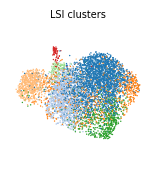

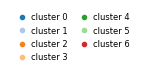

In [13]:
fig, ax = map_groups(xy, lsi, lsi_col, 'LSI clusters', S, legend=False)
save(fig, 'fig4a_lsi_clusters')
fig = legend_panel(lsi_col, {c: f'cluster {c}' for c in lsi_col}, ncol=2)
save(fig, 'fig4a_legend')

## 3. Fig. 4b and Supplementary Fig. S4a: clonal probabilities and the VAF of the variants each clone carries

For every kept clone, $\pi$ (Fig. 4b shows Clones 1, 3 and 4, Supplementary Fig. S4a all nine); for every clone that carries variants, the observed VAF of those variants. Cells without reads at a variant have VAF 0.

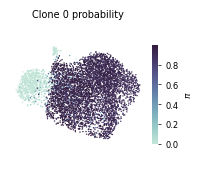

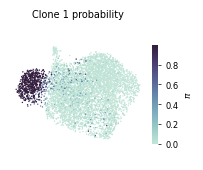

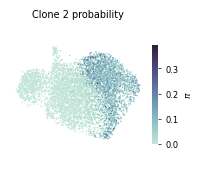

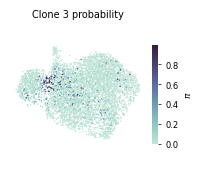

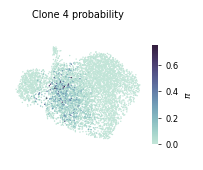

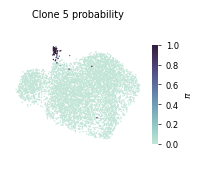

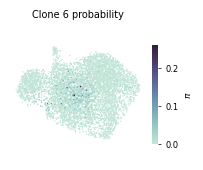

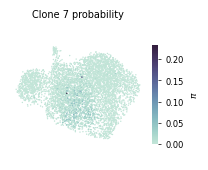

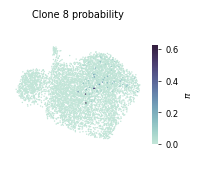

In [14]:
vaf = den(adata_mg.layers['VAF']).astype(float)
for k in range(pi.shape[1]):
    fig, ax = map_values(xy, pi[:, k], PI_CMAP, f'Clone {k} probability', r'$\pi$', S)
    save(fig, f'pi_clone{k}')

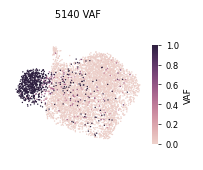

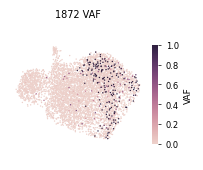

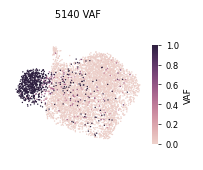

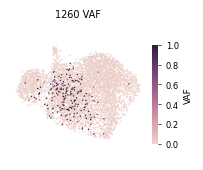

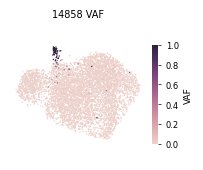

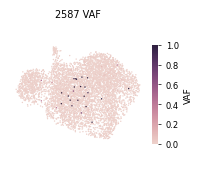

In [15]:
for k, muts in CARRIED.items():
    J = [list(variants).index(m) for m in muts]
    fig, ax = map_values(xy, vaf[:, J].mean(1), VAF_CMAP, ' + '.join(muts) + ' VAF', 'VAF', S)
    save(fig, f'vaf_clone{k}')

Clones 1 and 3 both carry 5140. Most 5140 mutant cells have a VAF close to 1 (Clone 1); setting the VAF above 0.9 to 0 shows the cells with intermediate VAF, where Clone 3 has its probability (Fig. 4b, middle).

In [16]:
v5140 = vaf[:, list(variants).index('5140')]
pd.Series({'5140 VAF > 0.9': int((v5140 > 0.9).sum()), '5140 VAF in (0, 0.9]': int(((v5140 > 0) & (v5140 <= 0.9)).sum()),
           f'phi of 5140, Clone {K5140[0]}': round(phi[j5140, K5140[0]], 3),
           f'phi of 5140, Clone {K5140[1]}': round(phi[j5140, K5140[1]], 3)})

5140 VAF > 0.9          736.000
5140 VAF in (0, 0.9]    569.000
phi of 5140, Clone 1      0.996
phi of 5140, Clone 3      0.432
dtype: float64

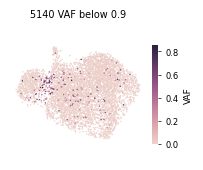

In [17]:
fig, ax = map_values(xy, np.where(v5140 > 0.9, 0, v5140), VAF_CMAP, '5140 VAF below 0.9', 'VAF', S)
save(fig, 'fig4b_vaf_5140_below0.9')

## 4. Fig. 4c: clone-specific allele frequencies $\phi$

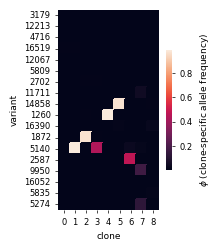

In [18]:
fig, ax = plt.subplots(figsize=(1.8, 2.6))
sns.heatmap(phi, yticklabels=variants, xticklabels=range(phi.shape[1]), square=True, ax=ax, linewidths=0.3,
            linecolor='face', cbar_kws={'label': r'$\phi$ (clone-specific allele frequency)', 'shrink': 0.6})
ax.tick_params(length=2)
ax.set_xlabel('clone')
ax.set_ylabel('variant')
save(fig, 'fig4c_phi')

## 5. Supplementary Fig. S4b: cells with high clonal probability

For each clone, the cells with the largest $\pi_{ck}$ that together account for 50% of the total probability of the clone (Methods). These cells are the "high" group and the other cells the "low" group of the accessibility comparison (step 4).

In [19]:
p32 = np.asarray(adata_mg.obsm['pi_deleted'])               # in the stored precision (float32), as the original analysis
sorted_desc = np.sort(p32, axis=0)[::-1]
cum = np.cumsum(sorted_desc, axis=0)
threshold = sorted_desc[np.argmax(cum >= 0.5 * cum[-1], axis=0), np.arange(p32.shape[1])]
high = p32 >= threshold
pd.DataFrame({'pi threshold': threshold, 'cells with high probability': high.sum(0),
              'share of the clone probability': (pi * high).sum(0) / pi.sum(0)}).round(3)

,pi threshold,cells with high probability,share of the clone probability
0,0.910,2210,0.500
1,0.975,367,0.501
2,0.091,766,0.500
3,0.289,165,0.501
4,0.131,296,0.500
5,1.000,29,0.503
6,0.021,248,0.501
7,0.016,298,0.500
8,0.081,43,0.503


.../site-packages/matplotlib/cbook/__init__.py:1062: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  x = np.asanyarray(x)
.../site-packages/matplotlib/cbook/__init__.py:1062: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  x = np.asanyarray(x)
.../site-packages/matplotlib/cbook/__init__.py:1062: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarra

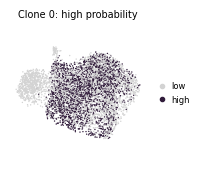

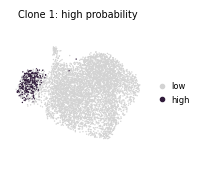

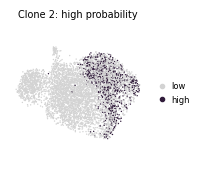

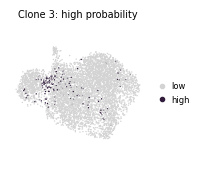

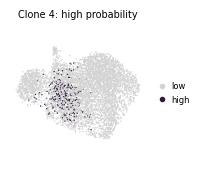

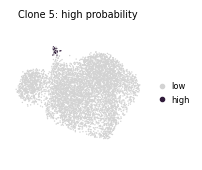

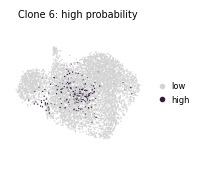

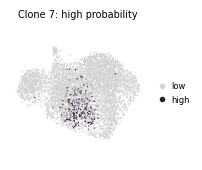

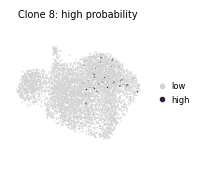

In [20]:
HIGH_COL = {False: '#d3d3d3', True: PI_CMAP(1.0)}
for k in range(pi.shape[1]):
    fig, ax = map_groups(xy, high[:, k], HIGH_COL, f'Clone {k}: high probability', S,
                         labels={False: 'low', True: 'high'})
    save(fig, f'supfig4b_high_clone{k}')

## 6. Supplementary Fig. S4c: $\pi$-weighted mean of the observed VAF and $\phi$

The $\pi$-weighted mean VAF of each variant in each clone, $\sum_c v_{cm}\pi_{ck} / \sum_c \pi_{ck}$, is computed from the data alone, next to the fitted allele frequency $\phi$.

In [21]:
vaf_pi = (vaf.T @ pi) / pi.sum(0)
pd.Series({'Pearson r': pearsonr(vaf_pi.ravel(), phi.ravel())[0], 'Spearman rho': spearmanr(vaf_pi.ravel(), phi.ravel())[0],
           'entries (variants x clones)': vaf_pi.size}).round(3)

Pearson r                        0.780
Spearman rho                     0.506
entries (variants x clones)    162.000
dtype: float64

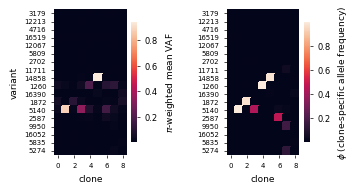

In [22]:
pd.DataFrame(vaf_pi, index=variants).round(3).to_csv(f'{OUT}/supfig4c_vaf_pi.csv')
fig, axes = plt.subplots(1, 2, figsize=(3.4, 2.6), gridspec_kw={'wspace': 0.9})
for ax, val, lab in [(axes[0], vaf_pi, r'$\pi$-weighted mean VAF'), (axes[1], phi, r'$\phi$ (clone-specific allele frequency)')]:
    sns.heatmap(val, square=True, ax=ax, linewidths=0.3, linecolor='face', yticklabels=variants,
                cbar_kws={'label': lab, 'shrink': 0.6})
    ax.set_xlabel('clone')
    ax.tick_params(length=2, labelsize=5)
axes[0].set_ylabel('variant')
save(fig, 'supfig4c_vaf_pi_and_phi')

## 7. Inputs of the R steps

The peak counts of the cells (peaks x cells, Matrix Market), with the peak and cell tables, for the gene activity (step 2) and the coverage plots (step 4); and the high-probability cells of each clone (column `clone_{k+1}` for Clone $k$, as read by the R scripts).

In [23]:
atac.obs.to_csv(f'{R_IN}/barcodes.tsv', sep='\t')
atac.var.to_csv(f'{R_IN}/features.tsv', sep='\t')
scipy.io.mmwrite(f'{R_IN}/matrix.mtx', atac.X.T)
flags = pd.DataFrame(high.astype(int), columns=[f'clone_{k + 1}' for k in range(pi.shape[1])])
flags.to_csv(f'{R_IN}/clone_flags.tsv', sep='\t')
atac.X.shape, int(atac.X.nnz), flags.sum().to_dict()

((5610, 107497),
 43994272,
 {'clone_1': 2210,
  'clone_2': 367,
  'clone_3': 766,
  'clone_4': 165,
  'clone_5': 296,
  'clone_6': 29,
  'clone_7': 248,
  'clone_8': 298,
  'clone_9': 43})

## 8. The numbers in the paper

The numbers of the CLL analysis quoted in the paper that this notebook computes, next to the computed values; the gene and accessibility results are checked in `03c` and `03d`. `where` names the part of the paper: the Results section, a figure legend or alt text, a supplementary table or the Methods subsection.

In [24]:
j5140 = list(variants).index('5140')
R, T2 = 'Results (CLL)', 'Supp. Table 2'
lp, lf = fit['lambda_pi, lambda_phi']
rows = [('kept clones', f'{R}; Supp. Fig. S4 legend', '9', str(pi.shape[1])),
        ('variants', f'{R}; Methods (Processing of MAESTER and CLL mutation data); {T2}; Fig. 4 alt text', '18', str(len(variants))),
        ('clones with the two largest phi of 5140', R, '1, 3', ', '.join(str(k) for k in sorted(K5140))),
        ('... both carry 5140 (phi > 0.2)', R, 'yes',
         'yes' if all('5140' in CARRIED.get(k, []) for k in K5140) else 'no'),
        ('... at different allele frequencies (phi of the two clones)', R, 'different',
         'different' if abs(phi[j5140, K5140[0]] - phi[j5140, K5140[1]]) > 0.2 else 'similar'),
        ('clone carrying 1260', f'{R}; Fig. 4 alt text', '4', str(K1260) if '1260' in CARRIED.get(K1260, []) else 'none'),
        ('high-probability cells: share of the clone probability', 'Methods (Downstream analysis of CLL mtscATAC-seq data); Supp. Fig. S4 legend', '50%',
         '50%' if np.all((pi * high).sum(0) / pi.sum(0) >= 0.5) else 'below 50%'),
        ('pi-weighted VAF correlates with phi', 'Supp. Fig. S4 legend', 'yes',
         'yes' if pearsonr(vaf_pi.ravel(), phi.ravel())[0] > 0.5 else 'no'),
        ('latent dimension L', 'Methods (Cell state inference)', str(max(10, int(F ** 0.25))), str(params['model_params']['xz_dim'])),
        ('hidden dimension', 'Methods (Cell state inference)', str(max(50, int(F ** 0.5))), str(params['model_params']['enc_z_h_dim'])),
        ('K', f'{T2}; Methods (Pruning of clones)', '20', str(params['model_params']['k'])),
        ('validation / test fraction', 'Methods (Loss function)', '0.05 / 0.1', f'{params["val_ratio"]} / {params["test_ratio"]}'),
        ('sample indicator', T2, 'none', 'none' if not params['use_multisamples'] else 'used'),
        ('decomposition of phi', T2, 'yes', 'yes' if params['model_params'].get('use_phi_common') else 'no'),
        ('regularization (gamma_pi, gamma_phi)', T2, '0.01, 1', f'{lp:g}, {lf:g}' if params['use_sparse_term'] else 'none')]
numbers = pd.DataFrame(rows, columns=['item', 'where', 'paper', 'computed'])
numbers['match'] = numbers['paper'] == numbers['computed']
numbers.to_csv(f'{OUT}/numbers_03a.csv', index=False)
pd.set_option('display.max_colwidth', 80)
numbers

,item,where,paper,computed,match
0,kept clones,Results (CLL); Supp. Fig. S4 legend,9,9,True
1,variants,Results (CLL); Methods (Processing of MAESTER and CLL mutation data); Supp. ...,18,18,True
2,clones with the two largest phi of 5140,Results (CLL),"1, 3","1, 3",True
3,... both carry 5140 (phi > 0.2),Results (CLL),yes,yes,True
4,... at different allele frequencies (phi of the two clones),Results (CLL),different,different,True
5,clone carrying 1260,Results (CLL); Fig. 4 alt text,4,4,True
6,high-probability cells: share of the clone probability,Methods (Downstream analysis of CLL mtscATAC-seq data); Supp. Fig. S4 legend,50%,50%,True
7,pi-weighted VAF correlates with phi,Supp. Fig. S4 legend,yes,yes,True
8,latent dimension L,Methods (Cell state inference),18,18,True
9,hidden dimension,Methods (Cell state inference),327,327,True


In [25]:
numbers['match'].all()

True